# Mammography Data Preparation

## 1. Introduction

### Objective

This notebook focuses on preparing the Mass and Calcification datasets for machine learning.

The preparation process includes:

- Loading the datasets.
- Handling missing values.
- Checking data consistency.
- Preparing categorical and numerical features.
- Preparing the target variable.
- Creating datasets ready for machine learning.

The original datasets will remain unchanged. All preparation steps will be performed on copies of the data.

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Datasets

We load the training datasets used during the data understanding phase.

In [71]:
mass_df = pd.read_csv("../data/mass_case_description_train_set.csv")
calc_df = pd.read_csv("../data/calc_case_description_train_set.csv")

calc_df = calc_df.rename(
    columns={"breast density": "breast_density"}
)

print("Mass Dataset:", mass_df.shape)
print("Calcification Dataset:", calc_df.shape)

Mass Dataset: (1318, 14)
Calcification Dataset: (1546, 14)


## 3. Missing Values Analysis

### Objective

Identify the missing values in each dataset and calculate their percentages.

This analysis will help us decide how to handle missing values without losing important information.

In [72]:
def missing_values_analysis(df, dataset_name):
    missing = pd.DataFrame({
        "Missing Values": df.isnull().sum(),
        "Percentage (%)": df.isnull().mean() * 100
    })

    missing = missing[missing["Missing Values"] > 0]

    print(f"\n{dataset_name}")
    if missing.empty:
        print("No missing values found.")
    else:
        print(missing.sort_values(
            by="Percentage (%)",
            ascending=False
        ))

missing_values_analysis(mass_df, "MASS DATASET")
missing_values_analysis(calc_df, "CALCIFICATION DATASET")


MASS DATASET
              Missing Values  Percentage (%)
mass margins              43        3.262519
mass shape                 4        0.303490

CALCIFICATION DATASET
                   Missing Values  Percentage (%)
calc distribution             376       24.320828
calc type                      20        1.293661


## 4. Missing Values Visualization

Visualize the percentage of missing values in both datasets to compare their distribution across clinical features.

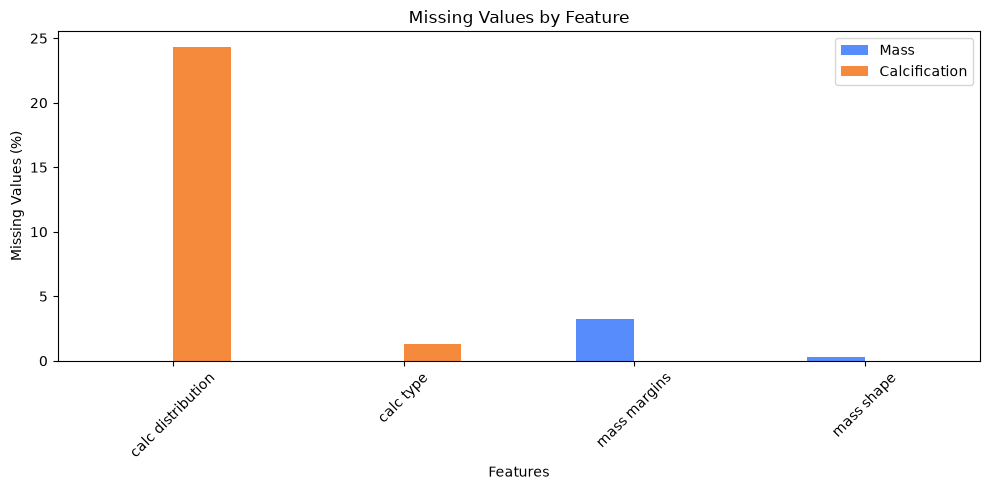

In [73]:
missing = pd.DataFrame({
    "Mass": mass_df.isnull().mean() * 100,
    "Calcification": calc_df.isnull().mean() * 100
})

missing = missing.loc[missing.max(axis=1) > 0]

missing.plot(kind="bar", figsize=(10, 5))

plt.title("Missing Values by Feature")
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Duplicate Records Analysis

### Objective

Identify exact duplicate records in both datasets.

Duplicate records may introduce redundancy and affect the quality of machine learning models.

In [74]:
print("MASS DATASET")
print("Exact duplicates:", mass_df.duplicated().sum())

print("\nCALCIFICATION DATASET")
print("Exact duplicates:", calc_df.duplicated().sum())

MASS DATASET
Exact duplicates: 0

CALCIFICATION DATASET
Exact duplicates: 0


In [75]:
print("MASS SHAPE")
print(mass_df["mass shape"].value_counts(dropna=False))

print("\nMASS MARGINS")
print(mass_df["mass margins"].value_counts(dropna=False))

MASS SHAPE
mass shape
IRREGULAR                                   351
OVAL                                        321
LOBULATED                                   305
ROUND                                       123
ARCHITECTURAL_DISTORTION                     80
IRREGULAR-ARCHITECTURAL_DISTORTION           45
LYMPH_NODE                                   26
ASYMMETRIC_BREAST_TISSUE                     20
FOCAL_ASYMMETRIC_DENSITY                     19
OVAL-LYMPH_NODE                               6
LOBULATED-IRREGULAR                           5
NaN                                           4
LOBULATED-LYMPH_NODE                          3
ROUND-OVAL                                    3
LOBULATED-ARCHITECTURAL_DISTORTION            2
IRREGULAR-FOCAL_ASYMMETRIC_DENSITY            2
LOBULATED-OVAL                                1
ROUND-IRREGULAR-ARCHITECTURAL_DISTORTION      1
ROUND-LOBULATED                               1
Name: count, dtype: int64

MASS MARGINS
mass margins
CIRCUMSCRIBED

In [76]:
print (mass_df[mass_df["mass shape"].isnull()])

    patient_id  breast_density left or right breast image view  \
287    P_00419               2                 LEFT         CC   
288    P_00419               2                 LEFT        MLO   
492    P_00710               2                RIGHT         CC   
493    P_00710               2                RIGHT        MLO   

     abnormality id abnormality type mass shape mass margins  assessment  \
287               2             mass        NaN  ILL_DEFINED           5   
288               1             mass        NaN  ILL_DEFINED           5   
492               1             mass        NaN          NaN           0   
493               1             mass        NaN          NaN           0   

     pathology  subtlety                                    image file path  \
287  MALIGNANT         5  Mass-Training_P_00419_LEFT_CC/1.3.6.1.4.1.9590...   
288  MALIGNANT         5  Mass-Training_P_00419_LEFT_MLO/1.3.6.1.4.1.959...   
492     BENIGN         0  Mass-Training_P_00710_RIG

## 6. Handling Missing Values in the Mass Dataset

### Objective

Handle missing values in the categorical features of the Mass Dataset while preserving as much useful information as possible.

Two features contain missing values:

- `mass shape`: 4 missing values (0.30%).
- `mass margins`: 43 missing values (3.26%).

After examining the affected records, we decided to preserve all observations and replace missing categorical values with an explicit `UNKNOWN` category.

This approach avoids unnecessary data loss and distinguishes missing information from existing clinical categories.

In [77]:
mass_df["mass shape"] = mass_df["mass shape"].fillna("UNKNOWN")

mass_df["mass margins"] = mass_df["mass margins"].fillna("UNKNOWN")

In [78]:
print("Remaining missing values:")
print(mass_df[["mass shape", "mass margins"]].isnull().sum())

print("\nMass Shape:")
print(mass_df["mass shape"].value_counts().head())

print("\nMass Margins:")
print(mass_df["mass margins"].value_counts().head())

Remaining missing values:
mass shape      0
mass margins    0
dtype: int64

Mass Shape:
mass shape
IRREGULAR                   351
OVAL                        321
LOBULATED                   305
ROUND                       123
ARCHITECTURAL_DISTORTION     80
Name: count, dtype: int64

Mass Margins:
mass margins
CIRCUMSCRIBED     305
SPICULATED        281
ILL_DEFINED       278
OBSCURED          197
MICROLOBULATED    108
Name: count, dtype: int64


### Key Findings

- All missing values in `mass shape` and `mass margins` were successfully handled.
- No observations were removed during the process.
- Missing categorical values were replaced with `UNKNOWN`.
- Existing clinical categories were preserved.

The Mass Dataset is now free of missing values in these two features.

## 7. Handling Missing Values in the Calcification Dataset

### Objective

Handle missing values in the categorical features of the Calcification Dataset while preserving the original observations.

Two features contain missing values:

- `calc type`: 20 missing values (1.29%).
- `calc distribution`: 376 missing values (24.32%).

The missing values will be examined before selecting an appropriate treatment strategy.

In [79]:
print("CALC TYPE")
print(calc_df["calc type"].value_counts(dropna=False))

print("\nCALC DISTRIBUTION")
print(calc_df["calc distribution"].value_counts(dropna=False))

CALC TYPE
calc type
PLEOMORPHIC                                                 664
AMORPHOUS                                                   138
PUNCTATE                                                    106
LUCENT_CENTER                                                93
VASCULAR                                                     82
FINE_LINEAR_BRANCHING                                        77
COARSE                                                       35
ROUND_AND_REGULAR-LUCENT_CENTER                              31
PLEOMORPHIC-FINE_LINEAR_BRANCHING                            28
ROUND_AND_REGULAR-LUCENT_CENTER-PUNCTATE                     24
ROUND_AND_REGULAR-EGGSHELL                                   23
PUNCTATE-PLEOMORPHIC                                         21
NaN                                                          20
DYSTROPHIC                                                   20
LUCENT_CENTERED                                              18
ROUND_AND_REGULAR   

In [80]:
print("Missing calc type by pathology:")
print(
    calc_df[calc_df["calc type"].isnull()]
    ["pathology"].value_counts()
)

print("\nMissing calc distribution by pathology:")
print(
    calc_df[calc_df["calc distribution"].isnull()]
    ["pathology"].value_counts()
)

Missing calc type by pathology:
pathology
BENIGN_WITHOUT_CALLBACK    18
BENIGN                      1
MALIGNANT                   1
Name: count, dtype: int64

Missing calc distribution by pathology:
pathology
BENIGN_WITHOUT_CALLBACK    371
BENIGN                       5
Name: count, dtype: int64


In [81]:
missing_dist = calc_df[calc_df["calc distribution"].isnull()]

print(
    missing_dist[
        ["calc type", "assessment", "subtlety", "pathology"]
    ].head(15)
)

                      calc type  assessment  subtlety                pathology
42                       COARSE           2         5  BENIGN_WITHOUT_CALLBACK
43                     VASCULAR           2         5  BENIGN_WITHOUT_CALLBACK
44                       COARSE           2         5  BENIGN_WITHOUT_CALLBACK
45                     VASCULAR           2         5  BENIGN_WITHOUT_CALLBACK
46                     VASCULAR           2         4  BENIGN_WITHOUT_CALLBACK
47                     VASCULAR           2         4  BENIGN_WITHOUT_CALLBACK
87                     VASCULAR           2         5  BENIGN_WITHOUT_CALLBACK
93                       COARSE           2         4  BENIGN_WITHOUT_CALLBACK
94                       COARSE           2         4  BENIGN_WITHOUT_CALLBACK
95   ROUND_AND_REGULAR-EGGSHELL           2         3  BENIGN_WITHOUT_CALLBACK
96   ROUND_AND_REGULAR-EGGSHELL           2         3  BENIGN_WITHOUT_CALLBACK
97   ROUND_AND_REGULAR-EGGSHELL           2         

### Observations

Further inspection of records with missing `calc distribution` revealed that other clinical features remain available.

Most of the inspected records belong to the `BENIGN_WITHOUT_CALLBACK` pathology class and have an assessment score of 2.

However, the available features are not sufficient to reliably reconstruct the missing clinical descriptors.

Therefore, missing values will be treated as `UNKNOWN` rather than artificially imputed.

### Missing Values Treatment Strategy

To preserve all observations and avoid introducing artificial clinical information, missing values in the following categorical features will be replaced with an explicit `UNKNOWN` category:

- `calc type`: 20 missing values.
- `calc distribution`: 376 missing values.

This approach preserves the original observations and distinguishes missing information from existing clinical categories.

In [82]:
calc_df["calc type"] = calc_df["calc type"].fillna("UNKNOWN")

calc_df["calc distribution"] = calc_df["calc distribution"].fillna("UNKNOWN")

In [83]:
print("Remaining missing values:")
print(
    calc_df[["calc type", "calc distribution"]]
    .isnull()
    .sum()
)

print("\nNew categories:")
print("Calc Type:", calc_df["calc type"].value_counts().get("UNKNOWN", 0))
print("Calc Distribution:", calc_df["calc distribution"].value_counts().get("UNKNOWN", 0))

Remaining missing values:
calc type            0
calc distribution    0
dtype: int64

New categories:
Calc Type: 20
Calc Distribution: 376


### Key Findings

- All missing values in `calc type` and `calc distribution` were successfully handled.
- 20 missing values in `calc type` were replaced with `UNKNOWN`.
- 376 missing values in `calc distribution` were replaced with `UNKNOWN`.
- No observations were removed.
- Existing clinical categories were preserved.

The Calcification Dataset is now free of missing values in these two features.

## 8. Data Consistency Checks

### Objective

Verify the consistency of numerical and categorical features before preparing the datasets for machine learning.

This step focuses on identifying unexpected values, invalid categories, and potential inconsistencies that may affect model training.

In [84]:
numeric_cols = ["breast_density", "assessment", "subtlety"]

print("MASS DATASET")
print(mass_df[numeric_cols].describe().loc[["min", "max"]])

print("\nCALCIFICATION DATASET")
print(calc_df[numeric_cols].describe().loc[["min", "max"]])

MASS DATASET
     breast_density  assessment  subtlety
min             1.0         0.0       0.0
max             4.0         5.0       5.0

CALCIFICATION DATASET
     breast_density  assessment  subtlety
min             1.0         0.0       1.0
max             4.0         5.0       5.0


### Numerical Features Consistency

The numerical features were checked against their observed value ranges.

- `breast_density` ranges from 1 to 4 in both datasets.
- `assessment` ranges from 0 to 5 in both datasets.
- `subtlety` ranges from 0 to 5 in the Mass Dataset and from 1 to 5 in the Calcification Dataset.

The zero values require further inspection before deciding whether they represent valid observations or missing information.

In [85]:
print("MASS DATASET")
print("Assessment = 0:", (mass_df["assessment"] == 0).sum())
print("Subtlety = 0:", (mass_df["subtlety"] == 0).sum())

print("\nCALCIFICATION DATASET")
print("Assessment = 0:", (calc_df["assessment"] == 0).sum())
print("Subtlety = 0:", (calc_df["subtlety"] == 0).sum())

MASS DATASET
Assessment = 0: 129
Subtlety = 0: 2

CALCIFICATION DATASET
Assessment = 0: 63
Subtlety = 0: 0


In [86]:
print("MASS DATASET - Assessment = 0")
print(
    mass_df[mass_df["assessment"] == 0][
        ["breast_density", "mass shape", "mass margins",
         "assessment", "subtlety", "pathology"]
    ].head(10)
)

print("\nCALCIFICATION DATASET - Assessment = 0")
print(
    calc_df[calc_df["assessment"] == 0][
        ["breast_density", "calc type", "calc distribution",
         "assessment", "subtlety", "pathology"]
    ].head(10)
)

MASS DATASET - Assessment = 0
     breast_density                mass shape   mass margins  assessment  \
38                2                 LOBULATED  CIRCUMSCRIBED           0   
47                2                      OVAL       OBSCURED           0   
48                2                      OVAL       OBSCURED           0   
56                2  ARCHITECTURAL_DISTORTION        UNKNOWN           0   
57                2  ARCHITECTURAL_DISTORTION        UNKNOWN           0   
93                2                      OVAL       OBSCURED           0   
94                2                      OVAL       OBSCURED           0   
188               3                     ROUND       OBSCURED           0   
204               3                 IRREGULAR    ILL_DEFINED           0   
229               2                      OVAL       OBSCURED           0   

     subtlety  pathology  
38          3     BENIGN  
47          5     BENIGN  
48          5     BENIGN  
56          4  MALIGNANT 

### Assessment Value Investigation

The value 0 was identified in the assessment feature of both datasets.

According to the BI-RADS classification system, category 0 indicates an incomplete assessment requiring additional imaging evaluation.

Therefore, zero values are considered meaningful categorical values rather than missing data.

No modifications will be applied to the assessment feature.

In [87]:
print(
    mass_df[mass_df["subtlety"] == 0][
        ["patient_id", "breast_density", "mass shape",
         "mass margins", "assessment", "subtlety", "pathology"]
    ]
)

    patient_id  breast_density mass shape mass margins  assessment  subtlety  \
492    P_00710               2    UNKNOWN      UNKNOWN           0         0   
493    P_00710               2    UNKNOWN      UNKNOWN           0         0   

    pathology  
492    BENIGN  
493    BENIGN  


### Subtlety Value Investigation

Two records in the Mass Dataset contain a subtlety value of 0.

Both records belong to the same patient (`P_00710`) and have missing mass shape and mass margins information.

Since the meaning of this value has not been confirmed, it will be preserved without modification for now.

These records will be considered during the subsequent feature preparation and model evaluation stages.

### Categorical Features Consistency

Check the unique values of categorical features to identify inconsistent labels, unexpected categories, or formatting differences.

This step helps ensure that categorical values are consistent before encoding them for machine learning.

In [88]:
categorical_cols = {
    "Mass": ["mass shape", "mass margins"],
    "Calcification": ["calc type", "calc distribution"]
}

for dataset_name, columns in categorical_cols.items():
    df = mass_df if dataset_name == "Mass" else calc_df

    print(f"\n{dataset_name.upper()} DATASET")

    for col in columns:
        print(f"\n{col}:")
        print(sorted(df[col].astype(str).unique()))


MASS DATASET

mass shape:
['ARCHITECTURAL_DISTORTION', 'ASYMMETRIC_BREAST_TISSUE', 'FOCAL_ASYMMETRIC_DENSITY', 'IRREGULAR', 'IRREGULAR-ARCHITECTURAL_DISTORTION', 'IRREGULAR-FOCAL_ASYMMETRIC_DENSITY', 'LOBULATED', 'LOBULATED-ARCHITECTURAL_DISTORTION', 'LOBULATED-IRREGULAR', 'LOBULATED-LYMPH_NODE', 'LOBULATED-OVAL', 'LYMPH_NODE', 'OVAL', 'OVAL-LYMPH_NODE', 'ROUND', 'ROUND-IRREGULAR-ARCHITECTURAL_DISTORTION', 'ROUND-LOBULATED', 'ROUND-OVAL', 'UNKNOWN']

mass margins:
['CIRCUMSCRIBED', 'CIRCUMSCRIBED-ILL_DEFINED', 'CIRCUMSCRIBED-MICROLOBULATED', 'CIRCUMSCRIBED-OBSCURED', 'ILL_DEFINED', 'ILL_DEFINED-SPICULATED', 'MICROLOBULATED', 'MICROLOBULATED-ILL_DEFINED', 'MICROLOBULATED-ILL_DEFINED-SPICULATED', 'MICROLOBULATED-SPICULATED', 'OBSCURED', 'OBSCURED-ILL_DEFINED', 'OBSCURED-ILL_DEFINED-SPICULATED', 'OBSCURED-SPICULATED', 'SPICULATED', 'UNKNOWN']

CALCIFICATION DATASET

calc type:
['AMORPHOUS', 'AMORPHOUS-PLEOMORPHIC', 'AMORPHOUS-ROUND_AND_REGULAR', 'COARSE', 'COARSE-LUCENT_CENTER', 'COARSE-

In [89]:
print("CALC TYPE - SUSPECTED VALUES")

for value in [
    "LUCENT_CENTER",
    "LUCENT_CENTERED",
    "PLEOMORPHIC-PLEOMORPHIC",
    "ROUND_AND_REGULAR-LUCENT_CENTER",
    "ROUND_AND_REGULAR-LUCENT_CENTERED"
]:
    print(value, ":", (calc_df["calc type"] == value).sum())

print("\nCALC DISTRIBUTION - SUSPECTED VALUES")

for value in ["REGIONAL", "REGIONAL-REGIONAL"]:
    print(value, ":", (calc_df["calc distribution"] == value).sum())

CALC TYPE - SUSPECTED VALUES
LUCENT_CENTER : 93
LUCENT_CENTERED : 18
PLEOMORPHIC-PLEOMORPHIC : 1
ROUND_AND_REGULAR-LUCENT_CENTER : 31
ROUND_AND_REGULAR-LUCENT_CENTERED : 14

CALC DISTRIBUTION - SUSPECTED VALUES
REGIONAL : 99
REGIONAL-REGIONAL : 1


### Categorical Values Investigation

The categorical features were inspected to identify inconsistent labels.

A few potential inconsistencies were identified:

- `LUCENT_CENTER` and `LUCENT_CENTERED` appear to be naming variants.
- `PLEOMORPHIC-PLEOMORPHIC` contains a repeated category.
- `REGIONAL-REGIONAL` contains a repeated category.

These values will be standardized to avoid treating equivalent labels as separate categories.

Other combined clinical descriptors will be preserved because they may contain meaningful information.

In [90]:
# Normalize Calcification Dataset categories

calc_df["calc type"] = (
    calc_df["calc type"]
    .str.replace("LUCENT_CENTERED", "LUCENT_CENTER", regex=False)
    .str.replace(
        "PLEOMORPHIC-PLEOMORPHIC",
        "PLEOMORPHIC",
        regex=False
    )
)

calc_df["calc distribution"] = (
    calc_df["calc distribution"]
    .replace({
        "REGIONAL-REGIONAL": "REGIONAL"
    })
)

In [91]:
print("LUCENT_CENTER:",
      (calc_df["calc type"] == "LUCENT_CENTER").sum())

print("LUCENT_CENTERED:",
      (calc_df["calc type"] == "LUCENT_CENTERED").sum())

print("PLEOMORPHIC-PLEOMORPHIC:",
      (calc_df["calc type"] == "PLEOMORPHIC-PLEOMORPHIC").sum())

print("\nREGIONAL:",
      (calc_df["calc distribution"] == "REGIONAL").sum())

print("REGIONAL-REGIONAL:",
      (calc_df["calc distribution"] == "REGIONAL-REGIONAL").sum())

LUCENT_CENTER: 111
LUCENT_CENTERED: 0
PLEOMORPHIC-PLEOMORPHIC: 0

REGIONAL: 100
REGIONAL-REGIONAL: 0


### Categorical Features Standardization

The identified categorical inconsistencies were successfully standardized.

- `LUCENT_CENTERED` was converted to `LUCENT_CENTER`.
- `PLEOMORPHIC-PLEOMORPHIC` was converted to `PLEOMORPHIC`.
- `REGIONAL-REGIONAL` was converted to `REGIONAL`.
- Combined clinical descriptors were preserved.

The categorical features are now standardized for the identified cases.

## 9. Feature Selection and Dataset Preparation

### 9.1 Feature Inspection

Before selecting the features, we inspect the available columns in both datasets to distinguish clinical information, identifiers, metadata, and target variables.

In [92]:
print("MASS DATASET COLUMNS")
print(mass_df.columns.tolist())

print("\nCALCIFICATION DATASET COLUMNS")
print(calc_df.columns.tolist())

MASS DATASET COLUMNS
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

CALCIFICATION DATASET COLUMNS
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


In [93]:
print("MASS DATASET")
print(mass_df["abnormality type"].value_counts(dropna=False))

print("\nCALCIFICATION DATASET")
print(calc_df["abnormality type"].value_counts(dropna=False))

MASS DATASET
abnormality type
mass    1318
Name: count, dtype: int64

CALCIFICATION DATASET
abnormality type
calcification    1546
Name: count, dtype: int64


### 9.2 Feature Selection Strategy

The following columns will be excluded from the machine learning features:

- `patient_id`: used for patient-level data splitting.
- `abnormality id`: technical identifier.
- `abnormality type`: constant within each dataset.
- Image file paths: not required for clinical feature-based models.

The following columns will be retained:

**Mass Dataset:**
- `breast_density`
- `left or right breast`
- `image view`
- `mass shape`
- `mass margins`
- `assessment`
- `subtlety`

**Calcification Dataset:**
- `breast_density`
- `left or right breast`
- `image view`
- `calc type`
- `calc distribution`
- `assessment`
- `subtlety`

The target variable is `pathology`.

The patient identifier will be kept separately to prevent data leakage during dataset splitting.

### 9.3 Creating the ML Datasets

Create separate datasets containing the selected clinical features and the target variable.

Patient identifiers are stored separately to support patient-level data splitting and prevent data leakage.

In [94]:
mass_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins",
    "assessment",
    "subtlety"
]

calc_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution",
    "assessment",
    "subtlety"
]

mass_ml = mass_df[mass_features + ["pathology"]].copy()
calc_ml = calc_df[calc_features + ["pathology"]].copy()

mass_patient_ids = mass_df["patient_id"].copy()
calc_patient_ids = calc_df["patient_id"].copy()

print("Mass ML Dataset:", mass_ml.shape)
print("Calcification ML Dataset:", calc_ml.shape)

Mass ML Dataset: (1318, 8)
Calcification ML Dataset: (1546, 8)


In [95]:
print("MASS ML DATASET")
display(mass_ml.head())

print("\nCALCIFICATION ML DATASET")
display(calc_ml.head())

print("\nMissing values:")
print("Mass:", mass_ml.isnull().sum().sum())
print("Calcification:", calc_ml.isnull().sum().sum())

MASS ML DATASET


,breast_density,left or right breast,image view,mass shape,mass margins,assessment,subtlety,pathology
0,3,LEFT,CC,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,4,MALIGNANT
1,3,LEFT,MLO,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,4,MALIGNANT
2,3,LEFT,CC,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,3,BENIGN
3,3,LEFT,MLO,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,3,BENIGN
4,3,RIGHT,MLO,OVAL,CIRCUMSCRIBED,4,5,BENIGN



CALCIFICATION ML DATASET


,breast_density,left or right breast,image view,calc type,calc distribution,assessment,subtlety,pathology
0,3,RIGHT,CC,AMORPHOUS,CLUSTERED,3,3,MALIGNANT
1,3,RIGHT,MLO,AMORPHOUS,CLUSTERED,3,3,MALIGNANT
2,4,LEFT,CC,PLEOMORPHIC,LINEAR,4,4,BENIGN
3,4,LEFT,MLO,PLEOMORPHIC,LINEAR,4,4,BENIGN
4,1,LEFT,CC,UNKNOWN,REGIONAL,2,3,BENIGN_WITHOUT_CALLBACK



Missing values:
Mass: 0
Calcification: 0


### Dataset Preparation Summary

Two machine learning datasets were successfully created:

- Mass Dataset: 1,318 observations and 8 columns.
- Calcification Dataset: 1,546 observations and 8 columns.

Each dataset contains seven clinical features and one target variable (`pathology`).

Patient identifiers were stored separately for patient-level data splitting.

No missing values remain in the selected features or target variables.

## 10. Categorical Feature Encoding

### 10.1 Understanding Feature Types

The selected features contain different types of categorical variables.

**Nominal features:** Categories without a natural order.
- `left or right breast`
- `image view`
- `mass shape`
- `mass margins`
- `calc type`
- `calc distribution`

**Ordinal features:** Categories with a meaningful order.
- `breast_density`
- `assessment`
- `subtlety`

The target variable `pathology` contains three classes:
- `BENIGN`
- `BENIGN_WITHOUT_CALLBACK`
- `MALIGNANT`

Different encoding strategies will be used according to the nature of each variable.

In [96]:
print("MASS ML DATASET")
print(mass_ml.dtypes)

print("\nCALCIFICATION ML DATASET")
print(calc_ml.dtypes)

MASS ML DATASET
breast_density          int64
left or right breast      str
image view                str
mass shape                str
mass margins              str
assessment              int64
subtlety                int64
pathology                 str
dtype: object

CALCIFICATION ML DATASET
breast_density          int64
left or right breast      str
image view                str
calc type                 str
calc distribution         str
assessment              int64
subtlety                int64
pathology                 str
dtype: object


### 10.2 Encoding Strategy

The encoding strategy is based on the nature of each feature.

**Ordinal features:**
- `breast_density`
- `assessment`
- `subtlety`

These features will retain their numerical values because they represent ordered categories.

**Nominal features:**

One-Hot Encoding will be applied to categorical features without a natural order.

**Target variable:**

The `pathology` variable will be encoded into numerical class labels while preserving its three original classes.

In [97]:
mass_nominal = [
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins"
]

calc_nominal = [
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution"
]

mass_encoded = pd.get_dummies(
    mass_ml,
    columns=mass_nominal,
    dtype=int
)

calc_encoded = pd.get_dummies(
    calc_ml,
    columns=calc_nominal,
    dtype=int
)

print("Mass encoded shape:", mass_encoded.shape)
print("Calcification encoded shape:", calc_encoded.shape)

Mass encoded shape: (1318, 43)
Calcification encoded shape: (1546, 59)


In [98]:
print("MASS ENCODED DATASET")
display(mass_encoded.head())

print("\nCALCIFICATION ENCODED DATASET")
display(calc_encoded.head())

print("\nTarget variable:")
print("Mass:", mass_encoded["pathology"].unique())
print("Calcification:", calc_encoded["pathology"].unique())

MASS ENCODED DATASET


,breast_density,assessment,subtlety,pathology,left or right breast_LEFT,left or right breast_RIGHT,image view_CC,image view_MLO,mass shape_ARCHITECTURAL_DISTORTION,mass shape_ASYMMETRIC_BREAST_TISSUE,...,mass margins_MICROLOBULATED,mass margins_MICROLOBULATED-ILL_DEFINED,mass margins_MICROLOBULATED-ILL_DEFINED-SPICULATED,mass margins_MICROLOBULATED-SPICULATED,mass margins_OBSCURED,mass margins_OBSCURED-ILL_DEFINED,mass margins_OBSCURED-ILL_DEFINED-SPICULATED,mass margins_OBSCURED-SPICULATED,mass margins_SPICULATED,mass margins_UNKNOWN
0,3,4,4,MALIGNANT,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,3,4,4,MALIGNANT,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
2,3,4,3,BENIGN,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,3,4,3,BENIGN,1,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,3,4,5,BENIGN,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0



CALCIFICATION ENCODED DATASET


,breast_density,assessment,subtlety,pathology,left or right breast_LEFT,left or right breast_RIGHT,image view_CC,image view_MLO,calc type_AMORPHOUS,calc type_AMORPHOUS-PLEOMORPHIC,...,calc type_VASCULAR-COARSE-LUCENT_CENTER-ROUND_AND_REGULAR-PUNCTATE,calc distribution_CLUSTERED,calc distribution_CLUSTERED-LINEAR,calc distribution_CLUSTERED-SEGMENTAL,calc distribution_DIFFUSELY_SCATTERED,calc distribution_LINEAR,calc distribution_LINEAR-SEGMENTAL,calc distribution_REGIONAL,calc distribution_SEGMENTAL,calc distribution_UNKNOWN
0,3,3,3,MALIGNANT,0,1,1,0,1,0,...,0,1,0,0,0,0,0,0,0,0
1,3,3,3,MALIGNANT,0,1,0,1,1,0,...,0,1,0,0,0,0,0,0,0,0
2,4,4,4,BENIGN,1,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,4,4,BENIGN,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
4,1,2,3,BENIGN_WITHOUT_CALLBACK,1,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0



Target variable:
Mass: <StringArray>
['MALIGNANT', 'BENIGN', 'BENIGN_WITHOUT_CALLBACK']
Length: 3, dtype: str
Calcification: <StringArray>
['MALIGNANT', 'BENIGN', 'BENIGN_WITHOUT_CALLBACK']
Length: 3, dtype: str


### 10.4 Target Variable Encoding

The target variable `pathology` contains three categorical classes.

Label encoding will convert these classes into numerical labels while preserving the original class names through a mapping.

This transformation is necessary for machine learning algorithms that require numerical target values.

In [99]:
pathology_mapping = {
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 1,
    "MALIGNANT": 2
}

mass_encoded["pathology"] = mass_encoded["pathology"].map(pathology_mapping)
calc_encoded["pathology"] = calc_encoded["pathology"].map(pathology_mapping)

print("Pathology Mapping:", pathology_mapping)

print("\nMass Target Classes:")
print(sorted(mass_encoded["pathology"].unique()))

print("\nCalcification Target Classes:")
print(sorted(calc_encoded["pathology"].unique()))

Pathology Mapping: {'BENIGN': 0, 'BENIGN_WITHOUT_CALLBACK': 1, 'MALIGNANT': 2}

Mass Target Classes:
[np.int64(0), np.int64(1), np.int64(2)]

Calcification Target Classes:
[np.int64(0), np.int64(1), np.int64(2)]


### Key Findings

- Nominal categorical features were successfully transformed using One-Hot Encoding.
- Ordinal numerical features retained their original values.
- The target variable `pathology` was encoded into three numerical classes.
- All three original pathology classes were preserved.

The datasets are now numerically represented, but the final preprocessing workflow will use a train/test split before fitting the encoders to prevent data leakage.

### 10.5 Patient-Level Train/Test Split

The datasets contain multiple observations from the same patients.

To prevent data leakage, the train/test split will be performed at the patient level.

GroupShuffleSplit will ensure that all observations belonging to the same patient remain in the same subset.

We will use:
- 80% for training.
- 20% for testing.

In [100]:
from sklearn.model_selection import StratifiedGroupKFold

def split_by_patient(df, patient_ids):
    X = df.drop(columns=["pathology"])
    y = df["pathology"]

    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=patient_ids)
    )

    return (
        X.iloc[train_idx].copy(),
        X.iloc[test_idx].copy(),
        y.iloc[train_idx].copy(),
        y.iloc[test_idx].copy(),
        patient_ids.iloc[train_idx].copy(),
        patient_ids.iloc[test_idx].copy(),
        train_idx,
        test_idx
    )


(
    mass_X_train, mass_X_test,
    mass_y_train, mass_y_test,
    mass_patient_train, mass_patient_test,
    mass_train_idx, mass_test_idx
) = split_by_patient(mass_ml, mass_patient_ids)


(
    calc_X_train, calc_X_test,
    calc_y_train, calc_y_test,
    calc_patient_train, calc_patient_test,
    calc_train_idx, calc_test_idx
) = split_by_patient(calc_ml, calc_patient_ids)

In [101]:
mass_train_patients = set(mass_patient_ids.iloc[mass_X_train.index])
mass_test_patients = set(mass_patient_ids.iloc[mass_X_test.index])

calc_train_patients = set(calc_patient_ids.iloc[calc_X_train.index])
calc_test_patients = set(calc_patient_ids.iloc[calc_X_test.index])

print("MASS DATASET")
print("Patients in both sets:", len(mass_train_patients & mass_test_patients))

print("\nCALCIFICATION DATASET")
print("Patients in both sets:", len(calc_train_patients & calc_test_patients))

MASS DATASET
Patients in both sets: 0

CALCIFICATION DATASET
Patients in both sets: 0


### 10.6 Train/Test Split Validation

The patient-level train/test split was successfully validated.

- No patients are shared between the training and testing sets.
- All observations belonging to the same patient remain in the same subset.
- The datasets preserve approximately an 80/20 training/testing distribution.

This strategy reduces the risk of data leakage and provides a more reliable evaluation of model performance.

### 10.7 Target Class Distribution

Analyze the distribution of pathology classes in the training and testing sets to identify potential class imbalance.

This comparison helps ensure that the evaluation sets contain representative samples of each class.

In [102]:
print("MASS DATASET")
print("\nTraining Set:")
print(mass_y_train.value_counts())

print("\nTesting Set:")
print(mass_y_test.value_counts())


print("\nCALCIFICATION DATASET")
print("\nTraining Set:")
print(calc_y_train.value_counts())

print("\nTesting Set:")
print(calc_y_test.value_counts())

MASS DATASET

Training Set:
pathology
MALIGNANT                  510
BENIGN                     461
BENIGN_WITHOUT_CALLBACK     83
Name: count, dtype: int64

Testing Set:
pathology
MALIGNANT                  127
BENIGN                     116
BENIGN_WITHOUT_CALLBACK     21
Name: count, dtype: int64

CALCIFICATION DATASET

Training Set:
pathology
MALIGNANT                  435
BENIGN                     423
BENIGN_WITHOUT_CALLBACK    379
Name: count, dtype: int64

Testing Set:
pathology
MALIGNANT                  109
BENIGN                     105
BENIGN_WITHOUT_CALLBACK     95
Name: count, dtype: int64


In [103]:
mass_train_patients = set(mass_patient_ids.iloc[mass_X_train.index])
mass_test_patients = set(mass_patient_ids.iloc[mass_X_test.index])

calc_train_patients = set(calc_patient_ids.iloc[calc_X_train.index])
calc_test_patients = set(calc_patient_ids.iloc[calc_X_test.index])

print("Mass overlap:", len(mass_train_patients & mass_test_patients))
print("Calcification overlap:", len(calc_train_patients & calc_test_patients))

Mass overlap: 0
Calcification overlap: 0


### Key Findings

- StratifiedGroupKFold was used to improve the train/test split.
- The three pathology classes are now more proportionally represented.
- The Mass and Calcification datasets preserve similar class distributions across both subsets.
- Patient-level separation is maintained to prevent data leakage.

The datasets are now ready for the preprocessing and encoding pipeline.

## 11. Preprocessing Pipeline

### 11.1 Encoding Categorical Features

Machine learning algorithms require numerical input.

The nominal categorical features will be transformed using One-Hot Encoding.

To prevent data leakage, the encoder will be fitted only on the training data and then applied to both training and testing sets.

Ordinal numerical features will retain their original values.

In [104]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

mass_nominal = [
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins"
]

calc_nominal = [
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution"
]

mass_preprocessor = ColumnTransformer(
    transformers=[
        ("nominal", OneHotEncoder(handle_unknown="ignore"), mass_nominal)
    ],
    remainder="passthrough"
)

calc_preprocessor = ColumnTransformer(
    transformers=[
        ("nominal", OneHotEncoder(handle_unknown="ignore"), calc_nominal)
    ],
    remainder="passthrough"
)

### 11.2 Applying One-Hot Encoding

The preprocessors are fitted using only the training data.

The fitted preprocessors are then used to transform both training and testing sets.

This ensures that the testing data does not influence the encoding process.

In [105]:
mass_X_train_encoded = mass_preprocessor.fit_transform(mass_X_train)
mass_X_test_encoded = mass_preprocessor.transform(mass_X_test)

calc_X_train_encoded = calc_preprocessor.fit_transform(calc_X_train)
calc_X_test_encoded = calc_preprocessor.transform(calc_X_test)

print("MASS DATASET")
print("Train:", mass_X_train_encoded.shape)
print("Test:", mass_X_test_encoded.shape)

print("\nCALCIFICATION DATASET")
print("Train:", calc_X_train_encoded.shape)
print("Test:", calc_X_test_encoded.shape)

MASS DATASET
Train: (1054, 40)
Test: (264, 40)

CALCIFICATION DATASET
Train: (1237, 52)
Test: (309, 52)


### Key Findings

- One-Hot Encoding was successfully applied to nominal categorical features.
- The preprocessors were fitted exclusively on the training sets.
- Training and testing sets have identical feature dimensions.
- Unknown categories in the testing sets are handled using `handle_unknown="ignore"`.

The categorical features are now numerically encoded without introducing data leakage.

## Saving Preprocessing Objects

The fitted preprocessing objects are saved to ensure consistent feature transformation during external evaluation.

The same encoders will be reused to transform the official test datasets without fitting them again.

In [106]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    mass_preprocessor,
    "../models/mass_preprocessor.joblib"
)

joblib.dump(
    calc_preprocessor,
    "../models/calc_preprocessor.joblib"
)

print("Preprocessing objects saved successfully.")

Preprocessing objects saved successfully.


### 11.3 Target Variable Encoding

The target variable `pathology` contains three distinct classes.

A consistent numerical mapping will be applied to the training and testing targets:

- BENIGN: 0
- BENIGN_WITHOUT_CALLBACK: 1
- MALIGNANT: 2

This transformation prepares the target variables for machine learning algorithms.

In [107]:
pathology_mapping = {
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 1,
    "MALIGNANT": 2
}

mass_y_train_encoded = mass_y_train.map(pathology_mapping)
mass_y_test_encoded = mass_y_test.map(pathology_mapping)

calc_y_train_encoded = calc_y_train.map(pathology_mapping)
calc_y_test_encoded = calc_y_test.map(pathology_mapping)

print("Mass classes:", sorted(mass_y_train_encoded.unique()))
print("Calcification classes:", sorted(calc_y_train_encoded.unique()))

Mass classes: [np.int64(0), np.int64(1), np.int64(2)]
Calcification classes: [np.int64(0), np.int64(1), np.int64(2)]


### 11.4 Final Preprocessing Summary

The preprocessing pipeline has been successfully applied to both datasets.

**Completed operations:**

- Missing values were handled using the `UNKNOWN` category.
- Inconsistent categorical labels were standardized.
- Clinical features were selected.
- Patient-level train/test splitting was performed.
- Nominal categorical features were encoded using One-Hot Encoding.
- Target classes were mapped to numerical labels.

**Final datasets:**

- Mass Dataset: encoded training and testing features.
- Calcification Dataset: encoded training and testing features.

All preprocessing transformations were fitted using training data only.

The datasets are now ready for machine learning experiments.

### 11.5 Final Dataset Verification

Verify the dimensions and missing values of the prepared datasets before saving them for subsequent machine learning experiments.

In [108]:
from scipy.sparse import issparse

datasets = {
    "Mass Train": mass_X_train_encoded,
    "Mass Test": mass_X_test_encoded,
    "Calcification Train": calc_X_train_encoded,
    "Calcification Test": calc_X_test_encoded
}

for name, data in datasets.items():
    print(f"{name}: {data.shape}")

print("\nMissing values:")

for name, data in datasets.items():
    if issparse(data):
        missing = np.isnan(data.data).sum()
    else:
        missing = np.isnan(data).sum()

    print(f"{name}: {missing}")

Mass Train: (1054, 40)
Mass Test: (264, 40)
Calcification Train: (1237, 52)
Calcification Test: (309, 52)

Missing values:
Mass Train: 0
Mass Test: 0
Calcification Train: 0
Calcification Test: 0


### 11.6 Saving Prepared Datasets

Save the prepared features and target variables for both Mass and Calcification datasets.

The saved files will be reused in subsequent machine learning experiments.

In [109]:
import os
from scipy.sparse import save_npz

os.makedirs("../data/processed", exist_ok=True)

# Save features
save_npz("../data/processed/mass_X_train.npz", mass_X_train_encoded)
save_npz("../data/processed/mass_X_test.npz", mass_X_test_encoded)

save_npz("../data/processed/calc_X_train.npz", calc_X_train_encoded)
save_npz("../data/processed/calc_X_test.npz", calc_X_test_encoded)

# Save target variables
np.save("../data/processed/mass_y_train.npy", mass_y_train_encoded)
np.save("../data/processed/mass_y_test.npy", mass_y_test_encoded)

np.save("../data/processed/calc_y_train.npy", calc_y_train_encoded)
np.save("../data/processed/calc_y_test.npy", calc_y_test_encoded)

# Save patient IDs
np.save("../data/processed/mass_patient_train.npy", mass_patient_train.to_numpy())
np.save("../data/processed/mass_patient_test.npy", mass_patient_test.to_numpy())

np.save("../data/processed/calc_patient_train.npy", calc_patient_train.to_numpy())
np.save("../data/processed/calc_patient_test.npy", calc_patient_test.to_numpy())

# Save original row indices
np.save("../data/processed/mass_train_idx.npy", mass_train_idx)
np.save("../data/processed/calc_train_idx.npy", calc_train_idx)

print("Prepared datasets and patient information saved successfully.")

Prepared datasets and patient information saved successfully.


### 11.7 Data Preparation Summary

The data preparation process has been completed successfully.

**Main operations:**

1. Handled missing values using an explicit `UNKNOWN` category.
2. Standardized inconsistent categorical labels.
3. Selected relevant clinical features.
4. Performed patient-level train/test splitting.
5. Applied One-Hot Encoding to nominal features.
6. Encoded the three pathology classes.
7. Verified the absence of missing values.
8. Saved the prepared datasets for future experiments.

**Final dataset dimensions:**

| Dataset | Training Samples | Testing Samples | Features |
|---|---:|---:|---:|
| Mass | 1054 | 264 | 40 |
| Calcification | 1237 | 309 | 52 |

The prepared datasets are ready for subsequent machine learning experiments.